# Bond Pricing & Yield Curve Risk Engine | Phases 1 + 2 + 3

**Goal:** build and independently check fixed-rate bond valuation, yield to maturity, duration, convexity, DV01, key-rate DV01 and portfolio scenario analysis using Python.

**Important:** The spot curve and all bonds in Phase 1 are **illustrative**, not live market quotes. We use continuous-compounded zero-coupon spot rates to value cash flows, and separately calculate a bond-equivalent nominal YTM with coupon frequency compounding. Both conventions are clearly distinguished.

**Model conventions:** settlement is immediately after a coupon date; first coupon occurs after one regular coupon period; no accrued interest, taxes, defaults, calls or bid-ask spreads. Coupon periods are regular, and maturity × coupon frequency must be an integer. Prices are **dirty = clean** only under this simplified settlement assumption. Phase 2 below uses an ECB-sourced zero-curve snapshot, downloaded at run time, while preserving the illustrative Phase 1 baseline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy.optimize import brentq
from pathlib import Path

OUT = Path("figures")
OUT.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda z: f"{z:,.4f}")

## 1. Define bonds and a continuously-compounded spot curve

The curve is linearly interpolated in **zero-rate space**. This is an explicit modelling assumption, not a market bootstrapping method. Maturity values are years. Each bond's `quantity` is the total face amount invested, with price expressed per 100 face.

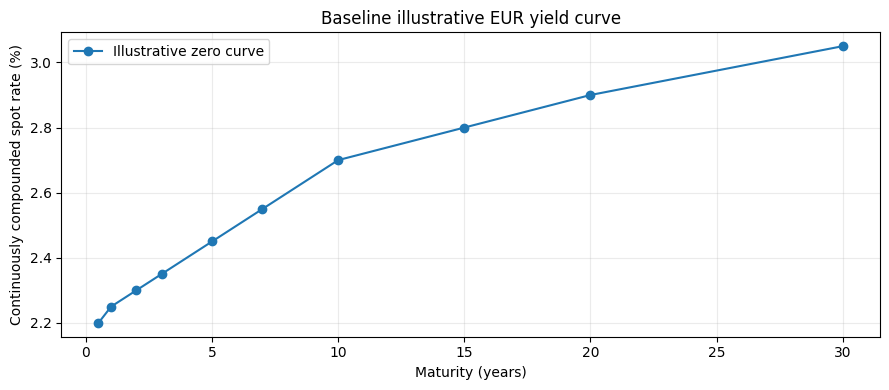

In [2]:
@dataclass(frozen=True)
class Bond:
    name: str
    maturity: float          # years
    coupon: float            # annual rate, decimal
    frequency: int = 2       # coupon payments per year
    face: float = 100.0
    quantity: float = 1_000_000.0  # portfolio face exposure in EUR

    def cashflows(self):
        periods = self.maturity * self.frequency
        if abs(periods - round(periods)) > 1e-9:
            raise ValueError(f"{self.name}: maturity is not a whole coupon period")
        if self.frequency not in (1, 2, 4):
            raise ValueError("Coupon frequency must be 1, 2 or 4")
        if self.maturity <= 0 or self.face <= 0 or self.quantity < 0 or self.coupon < 0:
            raise ValueError("Invalid bond characteristics")
        n = int(round(periods))
        times = np.arange(1, n + 1) / self.frequency
        cash = np.full(n, self.face * self.coupon / self.frequency)
        cash[-1] += self.face
        return times, cash

TENORS = np.array([0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30], dtype=float)
# Artificial term structure in decimals, NOT ECB data
BASE_ZERO = np.array([.022, .0225, .023, .0235, .0245, .0255, .027, .028, .029, .0305])
assert np.all(np.diff(TENORS)>0)

def spot(t, tenors=TENORS, rates=BASE_ZERO):
    t = np.asarray(t,dtype=float)
    if np.any(t < tenors[0]) or np.any(t > tenors[-1]):
        raise ValueError("Cash flow maturity is outside the supplied spot curve")
    return np.interp(t, tenors, rates)

bonds = [
    Bond("2Y sovereign-style", 2, .020, 2, quantity=1_500_000),
    Bond("5Y sovereign-style", 5, .030, 2, quantity=2_000_000),
    Bond("10Y sovereign-style",10, .035, 2, quantity=2_500_000),
    Bond("20Y sovereign-style",20, .040, 2, quantity=1_000_000),
]
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(TENORS,100*BASE_ZERO,"o-",label="Illustrative zero curve")
ax.set(xlabel="Maturity (years)",ylabel="Continuously compounded spot rate (%)",title="Baseline illustrative EUR yield curve")
ax.grid(alpha=.25);ax.legend();plt.tight_layout()
plt.savefig(OUT/"baseline_spot_curve.png",dpi=175,bbox_inches="tight")
plt.show()

## 2. Present value, YTM, Macaulay and modified duration, convexity

For each cash flow \(CF_i\) at time \(t_i\), the spot-curve price is \(P=\sum_i CF_i e^{-z(t_i)t_i}\). For YTM, \(P=\sum_i CF_i / (1+y/f)^{ft_i}\), where \(f\) is coupon frequency. Spot-curve DV01 and YTM DV01 are **different sensitivities**, so we compute both explicitly.

In [3]:
def price_from_curve(bond, zero_rates=BASE_ZERO, tenors=TENORS):
    t,cf=bond.cashflows()
    z=spot(t,tenors,zero_rates)
    return float(np.dot(cf,np.exp(-z*t)))

def price_from_ytm(bond, y):
    t,cf=bond.cashflows()
    base=1+y/bond.frequency
    if base<=0: raise ValueError("YTM below allowed domain")
    return float(np.sum(cf*base**(-bond.frequency*t)))

def solve_ytm(bond,price):
    if price<=0:raise ValueError("Price must be positive")
    # Domain lower bound just above -frequency; sufficiently high upper bound for positive prices.
    return brentq(lambda y: price_from_ytm(bond,y)-price,
                  -bond.frequency+1e-7, 10.0, xtol=1e-13)

def ytm_risk(bond,price=None):
    if price is None:price=price_from_curve(bond)
    y=solve_ytm(bond,price)
    t,cf=bond.cashflows()
    pv=cf*(1+y/bond.frequency)**(-bond.frequency*t)
    macaulay=float(np.dot(t,pv)/price)
    modified=macaulay/(1+y/bond.frequency)
    # Analytic modified convexity for periodic compounding:
    convexity=float(np.sum(pv*t*(t+1/bond.frequency))/price/(1+y/bond.frequency)**2)
    dy=1e-4
    finite_dv01=(price_from_ytm(bond,y-dy)-price_from_ytm(bond,y+dy))/2
    return dict(YTM=y, Macaulay=macaulay, Modified=modified,
                Convexity=convexity,DV01_YTM_exact=finite_dv01,
                DV01_YTM_linear=price*modified*dy)

def curve_dv01(bond,zero_rates=BASE_ZERO):
    bp=1e-4
    return (price_from_curve(bond,zero_rates-bp)-price_from_curve(bond,zero_rates+bp))/2

rows=[]
for b in bonds:
    price=price_from_curve(b)
    r=ytm_risk(b,price)
    rows.append({"Bond":b.name,"Coupon (%)":b.coupon*100,"Maturity":b.maturity,
                 "Price / 100":price,"YTM (%)":r['YTM']*100,
                 "Modified duration":r['Modified'],"Convexity":r['Convexity'],
                 "DV01 / 100 (curve)":curve_dv01(b),
                 "DV01 / 100 (YTM)":r['DV01_YTM_exact']})
bond_table=pd.DataFrame(rows).set_index("Bond")
display(bond_table.round(4))

,Coupon (%),Maturity,Price / 100,YTM (%),Modified duration,Convexity,DV01 / 100 (curve),DV01 / 100 (YTM)
Bond,,,,,,,,
2Y sovereign-style,2.0000,2,99.3925,2.3126,1.9479,4.7900,0.0196,0.0194
5Y sovereign-style,3.0000,5,102.5313,2.4589,4.6282,24.5920,0.0480,0.0475
10Y sovereign-style,3.5000,10,107.0606,2.6900,8.4693,83.1088,0.0918,0.0907
20Y sovereign-style,4.0000,20,117.2414,2.8618,14.2702,254.8848,0.1688,0.1673


## 3. Verify the engine with known identities

The identities below are automated unit tests, not just visual checks: a par bond at equal coupon/YTM must price at par, a zero-coupon bond has Macaulay duration equal to its maturity, YTM root-solving must recover its price, and finite-difference YTM DV01 must agree with its analytic duration approximation.

In [4]:
par=Bond("Par test",5,.04,2)
assert np.isclose(price_from_ytm(par,.04),100.0,atol=1e-10)
zero=Bond("Zero",5,0.0,2)
zero_price=price_from_ytm(zero,.03)
assert np.isclose(ytm_risk(zero,zero_price)['Macaulay'],5.0,atol=1e-10)
for b in bonds:
    P=price_from_curve(b)
    r=ytm_risk(b,P)
    assert np.isclose(price_from_ytm(b,r['YTM']),P,atol=1e-9)
    assert np.isclose(r['DV01_YTM_exact'],r['DV01_YTM_linear'],rtol=1e-6)
    assert curve_dv01(b)>0
    assert price_from_curve(b,BASE_ZERO+.01)<P
print("PASS: par bond, zero bond, YTM inversion, duration DV01, positive DV01, rate/price direction")

PASS: par bond, zero bond, YTM inversion, duration DV01, positive DV01, rate/price direction


## 4. Portfolio valuation and parallel, steepening and flattening shocks

Each position's market value equals `quantity × price / face`. Parallel shocks change **every zero rate** by the same number of basis points. Steepening and flattening shocks are constructed as linear shifts from the 0.5Y to 30Y nodes, not forecasts or observed market moves.

,Portfolio value (€),P&L (€),Return (%)
Scenario,,,
Base,"7,390,440.7100",0.0000,0.0000
Parallel +100bp,"6,893,788.6300","-496,652.0800",-6.7200
Parallel -100bp,"7,943,791.0400","553,350.3300",7.4900
Bear steepener,"6,951,277.7200","-439,162.9800",-5.9400
Bull flattener,"7,718,178.4900","327,737.7800",4.4300


Portfolio base market value: €7,390,440.71
Portfolio parallel DV01: €5,236.84 per 1bp


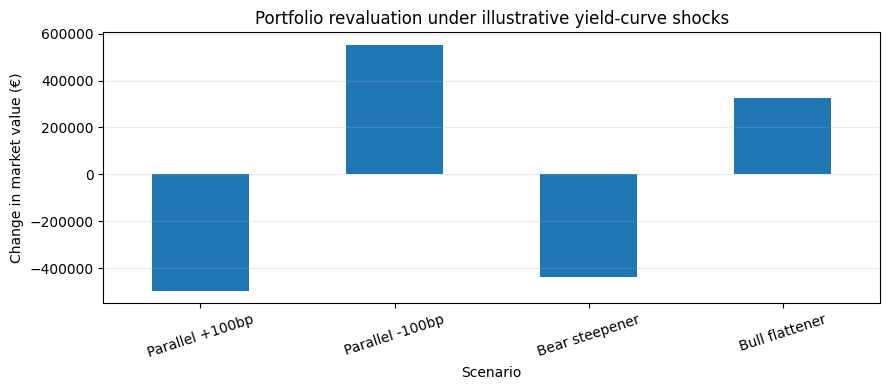

In [5]:
def portfolio_value(rates=BASE_ZERO):
    return sum(b.quantity*price_from_curve(b,rates)/b.face for b in bonds)

base_port=portfolio_value()
parallel_dv01=(portfolio_value(BASE_ZERO-1e-4)-portfolio_value(BASE_ZERO+1e-4))/2
scenario_shifts={
 "Base":np.zeros_like(TENORS),
 "Parallel +100bp":np.full_like(TENORS,.01),
 "Parallel -100bp":np.full_like(TENORS,-.01),
 "Bear steepener":np.linspace(.0025,.0125,len(TENORS)),
 "Bull flattener":np.linspace(-.0125,-.0025,len(TENORS)),
}
scenarios=pd.DataFrame([{"Scenario":name,"Portfolio value (€)":portfolio_value(BASE_ZERO+sh),
                          "P&L (€)":portfolio_value(BASE_ZERO+sh)-base_port,
                          "Return (%)":100*(portfolio_value(BASE_ZERO+sh)/base_port-1)}
                         for name,sh in scenario_shifts.items()]).set_index("Scenario")
display(scenarios.round(2))
print(f"Portfolio base market value: €{base_port:,.2f}")
print(f"Portfolio parallel DV01: €{parallel_dv01:,.2f} per 1bp")
fig,ax=plt.subplots(figsize=(9,4))
scenarios.drop(index="Base")["P&L (€)"].plot(kind="bar",ax=ax)
ax.set(title="Portfolio revaluation under illustrative yield-curve shocks",ylabel="Change in market value (€)")
ax.tick_params(axis="x",rotation=18)
ax.grid(axis="y",alpha=.25)
plt.tight_layout();plt.savefig(OUT/"portfolio_scenarios.png",dpi=175,bbox_inches="tight");plt.show()

## 5. Key-rate DV01: sensitivity to individual curve tenors

A one-node key-rate shock changes that one **quoted zero-rate node**, with the resulting spot-rate effect linearly interpolated between nodes. This is a **node DV01**, not a market-standard tent-shaped key-rate duration. With linear interpolation and no extrapolation, summing all node DV01s equals the parallel-curve DV01 to numerical precision.

,Tenor (years),Node DV01 (€ per bp)
0,0.5000,5.3800
1,1.0000,18.5200
2,2.0000,326.2200
3,3.0000,86.4000
4,5.0000,"1,027.3300"
5,7.0000,192.8500
6,10.0000,"2,145.2700"
7,15.0000,195.6600
8,20.0000,"1,239.2100"
9,30.0000,0.0000


Sum of node DV01: €5,236.84
Parallel DV01: €5,236.84


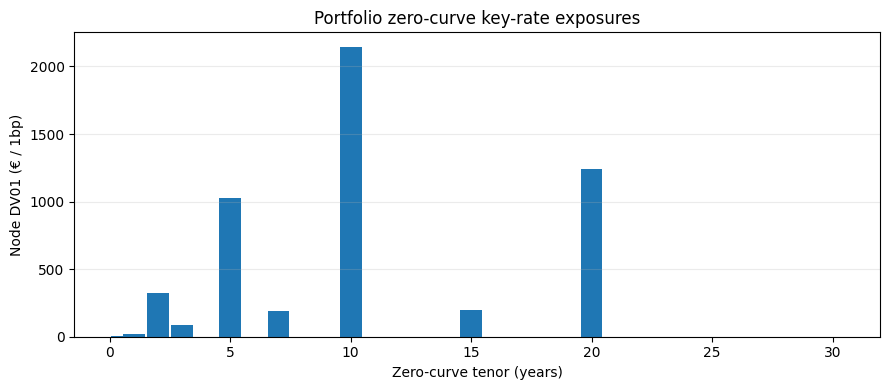

In [6]:
bp=1e-4
kr=[]
for i,tenor in enumerate(TENORS):
    up=BASE_ZERO.copy();down=BASE_ZERO.copy()
    up[i]+=bp;down[i]-=bp
    kr.append((portfolio_value(down)-portfolio_value(up))/2)
key_rates=pd.DataFrame({"Tenor (years)":TENORS,"Node DV01 (€ per bp)":kr})
display(key_rates.round(2))
print(f"Sum of node DV01: €{sum(kr):,.2f}")
print(f"Parallel DV01: €{parallel_dv01:,.2f}")
assert np.isclose(sum(kr),parallel_dv01,rtol=2e-6,atol=.01)
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(TENORS,kr,width=.9)
ax.set(xlabel="Zero-curve tenor (years)",ylabel="Node DV01 (€ / 1bp)",title="Portfolio zero-curve key-rate exposures")
ax.grid(axis="y",alpha=.25)
plt.tight_layout();plt.savefig(OUT/"key_rate_dv01.png",dpi=175,bbox_inches="tight");plt.show()

## 6. Duration and convexity approximation versus full repricing

For a small **parallel shift of a continuously compounded spot curve**, the portfolio dollar duration and convexity are computed from **discounted cash-flow times**, not from YTM modified duration. This is the appropriate first- and second-order approximation to the same spot-curve pricing function. Compare approximation error as shocks become larger.

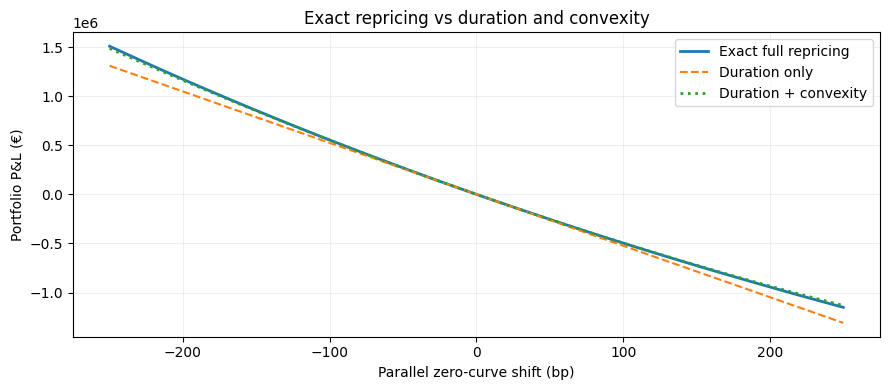

Modified duration to parallel continuous zero shift: 7.086 years
Continuous-zero convexity: 76.57 years²


In [7]:
def portfolio_curve_risk():
    duration_dollar=0.0
    convexity_dollar=0.0
    for b in bonds:
        t,cf=b.cashflows()
        pv=cf*np.exp(-spot(t)*t)*b.quantity/b.face
        duration_dollar+=np.dot(t,pv)
        convexity_dollar+=np.dot(t*t,pv)
    return float(duration_dollar),float(convexity_dollar)

D_dollar,C_dollar=portfolio_curve_risk()
shocks=np.linspace(-.025,.025,101)
exact=np.array([portfolio_value(BASE_ZERO+s)-base_port for s in shocks])
first=-D_dollar*shocks
second=first+.5*C_dollar*shocks**2
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(shocks*10000,exact,label="Exact full repricing",linewidth=2)
ax.plot(shocks*10000,first,"--",label="Duration only")
ax.plot(shocks*10000,second,":",label="Duration + convexity",linewidth=2)
ax.set(xlabel="Parallel zero-curve shift (bp)",ylabel="Portfolio P&L (€)",title="Exact repricing vs duration and convexity")
ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(OUT/"duration_convexity.png",dpi=175,bbox_inches="tight");plt.show()
assert np.isclose(D_dollar*1e-4,parallel_dv01,rtol=1e-5)
print(f"Modified duration to parallel continuous zero shift: {D_dollar/base_port:.3f} years")
print(f"Continuous-zero convexity: {C_dollar/base_port:.2f} years²")

## 7. Export summary tables and next steps

We now have a deterministic engine with basic unit tests. **Phase 2**, below, fetches the ECB AAA euro-area **zero-coupon spot** series, aligns observation dates and revalues the same cash flows. Later we can add coupon schedules by settlement date, accrued interest, day counts, bootstrapping, issuer spreads, credit risk, hedging and stress attribution.

**Important interpretation:** An ECB government **AAA zero curve** is a benchmark term structure, not each bond's credit- or liquidity-adjusted market curve. The sample bonds are synthetic and do not represent specific issued securities.

In [8]:
bond_table.to_csv("bond_risk_summary.csv")
scenarios.to_csv("portfolio_scenario_results.csv")
key_rates.to_csv("portfolio_key_rate_dv01.csv",index=False)
print("Created 3 CSV tables and 4 charts in figures/")

Created 3 CSV tables and 4 charts in figures/


## 8. Phase 2 | ECB AAA euro-area zero-coupon curve

We now replace the illustrative zero rates with **actual published ECB daily spot yields**. The bond cash flows, positions and pricing conventions remain unchanged. The ECB curves cover **AAA-rated central-government bonds from across the euro area**, not an executable quote for any individual bond.

- **Data:** `YC`, key family `B.U2.EUR.4F.G_N_A.SV_C_YM.SR_*`, 0.5Y through 30Y spot maturities.
- **Source:** [ECB Data Portal yield-curve dataset](https://data.ecb.europa.eu/data/datasets/YC) and [methodology](https://www.ecb.europa.eu/stats/financial_markets_and_interest_rates/euro_area_yield_curves/shared/pdf/technical_notes.pdf).
- **Convention:** ECB spot rates are **continuously compounded annualized rates**, published in **percent**. We divide by 100 to obtain the pricing engine's decimal rates.
- **Dates:** select the latest **single common observation date** for all maturities within the requested window. We never mix dates and never invent unavailable yields.
- **Interpolation:** as in Phase 1, linearly interpolate observed zero rates between nodes. This is a simplification of the ECB's Nelson-Siegel-Svensson fitted curve.

The following cell needs an internet connection. If the ECB API is unavailable, it raises an error rather than silently substituting the illustrative curve.

In [9]:
import io
import requests

TENOR_TO_SERIES = {0.5:"SR_6M",1:"SR_1Y",2:"SR_2Y",3:"SR_3Y",5:"SR_5Y",
                   7:"SR_7Y",10:"SR_10Y",15:"SR_15Y",20:"SR_20Y",30:"SR_30Y"}
ECB_START = "2026-10-01"
ECB_END = "2026-11-20"  # freeze this study's requested end date; update for a new as-of date
ECB_API = "https://data-api.ecb.europa.eu/service/data/YC/"
ECB_KEY_PREFIX = "B.U2.EUR.4F.G_N_A.SV_C_YM."

def parse_ecb_sdmx_csv(csv_text, mapping=TENOR_TO_SERIES):
    frame = pd.read_csv(io.StringIO(csv_text))
    required = {"TIME_PERIOD","OBS_VALUE"}
    if not required.issubset(frame.columns):
        raise ValueError(f"Unexpected ECB CSV schema. Columns: {list(frame.columns)}")
    if "DATA_TYPE_FM" in frame.columns:
        series = frame["DATA_TYPE_FM"].astype(str)
    elif "KEY" in frame.columns:
        series = frame["KEY"].astype(str).str.rsplit(".", n=1).str[-1]
    elif "SERIES_KEY" in frame.columns:
        series = frame["SERIES_KEY"].astype(str).str.rsplit(".", n=1).str[-1]
    else:
        raise ValueError("ECB response is missing its spot-tenor series identifier")
    tmp = pd.DataFrame({"date":pd.to_datetime(frame["TIME_PERIOD"],errors="coerce"),
                        "series":series,
                        "yield_pct":pd.to_numeric(frame["OBS_VALUE"],errors="coerce")})
    tmp = tmp.dropna(subset=["date","yield_pct"])
    tmp = tmp[tmp["series"].isin(mapping.values())]
    if tmp.empty:
        raise ValueError("No valid ECB AAA spot-rate observations found in response")
    wide = tmp.pivot_table(index="date",columns="series",values="yield_pct",aggfunc="last")
    expected = list(mapping.values())
    missing = sorted(set(expected)-set(wide.columns))
    if missing:
        raise ValueError(f"Missing ECB spot tenors in response: {missing}")
    common = wide[expected].dropna(how="any")
    if common.empty:
        raise ValueError("No observation date has every requested maturity; cannot form a matched-date curve")
    chosen = common.index.max()
    return chosen, pd.Series({tenor: float(common.loc[chosen,code])/100
                              for tenor,code in mapping.items()},name="zero_rate")

# Test parser with a miniature, fabricated CSV fixture (NOT market data).
fixture = "TIME_PERIOD,DATA_TYPE_FM,OBS_VALUE\n2026-11-19,SR_2Y,2.50\n2026-11-19,SR_10Y,3.00\n"
dt_test, series_test = parse_ecb_sdmx_csv(fixture,{2.0:"SR_2Y",10.0:"SR_10Y"})
assert dt_test.strftime("%Y-%m-%d")=="2026-11-19"
assert np.isclose(series_test.loc[2.0],.025)

key = ECB_KEY_PREFIX + "+".join(TENOR_TO_SERIES.values())
url = ECB_API + key
try:
    response = requests.get(url,params={"startPeriod":ECB_START,"endPeriod":ECB_END,"format":"csvdata"},
                            headers={"Accept":"text/csv"}, timeout=35)
    response.raise_for_status()
    ecb_date, ecb_series = parse_ecb_sdmx_csv(response.text)
except (requests.RequestException,ValueError) as exc:
    raise RuntimeError("Unable to download a complete ECB AAA zero-rate curve. "
                       "Check ECB API access, series, or requested dates; no illustrative "
                       "data have been substituted.") from exc

ECB_TENORS = np.array(sorted(TENOR_TO_SERIES), dtype=float)
ECB_ZERO = ecb_series.reindex(ECB_TENORS).to_numpy(dtype=float)
assert np.array_equal(ECB_TENORS,TENORS)
assert np.all(np.isfinite(ECB_ZERO))
assert ecb_date <= pd.Timestamp(ECB_END)
ecb_table = pd.DataFrame({"Tenor (years)": ECB_TENORS,
                          "ECB spot yield (%)": ECB_ZERO*100,
                          "Illustrative yield (%)":BASE_ZERO*100,
                          "Difference (bp)":(ECB_ZERO-BASE_ZERO)*10000})
print("ECB curve observation date:",ecb_date.date())
print("ECB source:",response.url)
display(ecb_table.round(3))
ecb_table.to_csv("ecb_aaa_spot_curve.csv",index=False)

ECB curve observation date: 2026-11-19
ECB source: https://data-api.ecb.europa.eu/service/data/YC/B.U2.EUR.4F.G_N_A.SV_C_YM.SR_6M+SR_1Y+SR_2Y+SR_3Y+SR_5Y+SR_7Y+SR_10Y+SR_15Y+SR_20Y+SR_30Y?startPeriod=2026-10-01&endPeriod=2026-11-20&format=csvdata


,Tenor (years),ECB spot yield (%),Illustrative yield (%),Difference (bp)
0,0.5000,2.8200,2.2000,62.0440
1,1.0000,3.0040,2.2500,75.4230
2,2.0000,3.1250,2.3000,82.5060
3,3.0000,3.1450,2.3500,79.5030
4,5.0000,3.1880,2.4500,73.8380
5,7.0000,3.2810,2.5500,73.1390
6,10.0000,3.4420,2.7000,74.1510
7,15.0000,3.6400,2.8000,83.9630
8,20.0000,3.7290,2.9000,82.9460
9,30.0000,3.6920,3.0500,64.2390


## 9. Compare the ECB spot curve against our illustrative term structure

We use the **same cash flows and holdings**. Differences in bond prices reflect changes in the curve, not changes in security characteristics. The sample bonds remain synthetic; resulting values are **model prices**, not traded market prices.

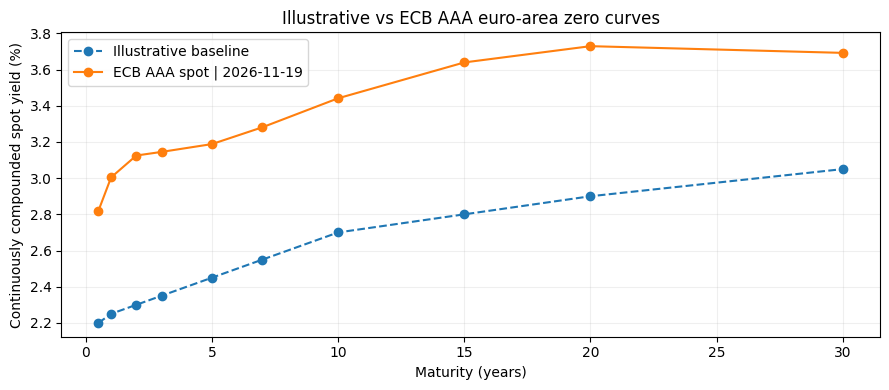

,Illustrative / 100,ECB / 100,Change / 100,ECB-implied YTM (%),ECB curve DV01 / 100
Bond,,,,,
2Y sovereign-style,99.3925,97.7921,-1.6004,3.1477,0.0193
5Y sovereign-style,102.5313,99.0359,-3.4954,3.2102,0.0463
10Y sovereign-style,107.0606,100.4807,-6.5799,3.4428,0.0856
20Y sovereign-style,117.2414,104.3918,-12.8496,3.6876,0.1462


In [10]:
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(TENORS,BASE_ZERO*100,"o--",label="Illustrative baseline")
ax.plot(ECB_TENORS,ECB_ZERO*100,"o-",label=f"ECB AAA spot | {ecb_date:%Y-%m-%d}")
ax.set(xlabel="Maturity (years)",ylabel="Continuously compounded spot yield (%)",
       title="Illustrative vs ECB AAA euro-area zero curves")
ax.grid(alpha=.2);ax.legend()
plt.tight_layout();plt.savefig(OUT/"ecb_vs_illustrative_spot_curve.png",dpi=180,bbox_inches="tight")
plt.show()

price_rows=[]
for bond in bonds:
    ref=price_from_curve(bond,BASE_ZERO,TENORS)
    market=price_from_curve(bond,ECB_ZERO,ECB_TENORS)
    ytm_ecb=solve_ytm(bond,market)
    ecbdv=(price_from_curve(bond,ECB_ZERO-1e-4,ECB_TENORS)-
           price_from_curve(bond,ECB_ZERO+1e-4,ECB_TENORS))/2
    price_rows.append({"Bond":bond.name,"Illustrative / 100":ref,
                       "ECB / 100":market,"Change / 100":market-ref,
                       "ECB-implied YTM (%)":ytm_ecb*100,
                       "ECB curve DV01 / 100":ecbdv})
ecb_bond_table=pd.DataFrame(price_rows).set_index("Bond")
display(ecb_bond_table.round(4))
ecb_bond_table.to_csv("ecb_repriced_bonds.csv")

## 10. Reprice the portfolio and shock the ECB curve

Scenarios are **hypothetical instantaneous shocks to the ECB reference curve**, not forecasts. We report actual full repricing alongside a first-order DV01 check for parallel moves.

,Portfolio value (€),P&L (€),Return (%)
Scenario,,,
Base,"7,003,533.8900",0.0000,0.0000
Parallel +100bp,"6,546,102.0700","-457,431.8200",-6.5300
Parallel -100bp,"7,511,727.0900","508,193.2000",7.2600
Bear steepener,"6,602,937.0000","-400,596.8900",-5.7200
Bull flattener,"7,309,281.2700","305,747.3800",4.3700


Illustrative baseline: €7,390,440.71
ECB curve as of 2026-11-19: €7,003,533.89
Change in model portfolio value: €-386,906.82
ECB portfolio DV01: €4,816.57 / bp
ECB effective duration to parallel continuous zero shift: 6.877 years
ECB effective convexity to parallel continuous zero shift: 72.347 years²


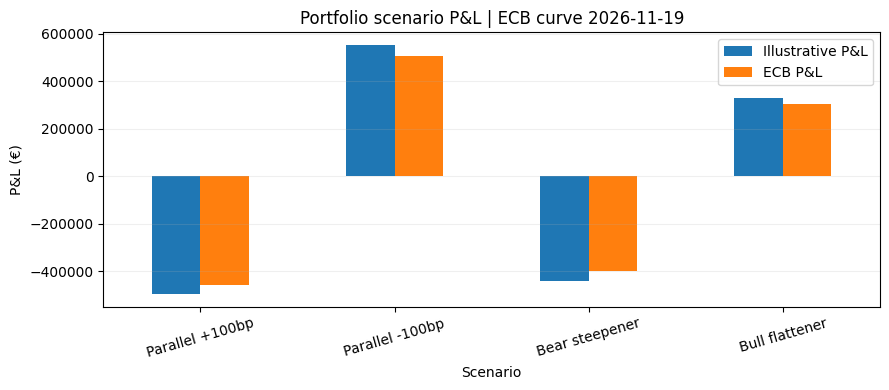

In [11]:
ecb_port=portfolio_value(ECB_ZERO)
ecb_parallel_dv01=(portfolio_value(ECB_ZERO-1e-4)-portfolio_value(ECB_ZERO+1e-4))/2
ecb_dollar_dur=0.0
ecb_dollar_conv=0.0
for bond in bonds:
    t,cf=bond.cashflows()
    pv=cf*np.exp(-spot(t,ECB_TENORS,ECB_ZERO)*t)*bond.quantity/bond.face
    ecb_dollar_dur+=float(np.dot(t,pv))
    ecb_dollar_conv+=float(np.dot(t*t,pv))
assert np.isclose(ecb_dollar_dur*1e-4,ecb_parallel_dv01,rtol=1e-5)

ecb_scenarios=pd.DataFrame([
    {"Scenario":name,"Portfolio value (€)":portfolio_value(ECB_ZERO+shift),
     "P&L (€)":portfolio_value(ECB_ZERO+shift)-ecb_port,
     "Return (%)":100*(portfolio_value(ECB_ZERO+shift)/ecb_port-1)}
    for name,shift in scenario_shifts.items()
]).set_index("Scenario")
display(ecb_scenarios.round(2))
print(f"Illustrative baseline: €{base_port:,.2f}")
print(f"ECB curve as of {ecb_date.date()}: €{ecb_port:,.2f}")
print(f"Change in model portfolio value: €{ecb_port-base_port:+,.2f}")
print(f"ECB portfolio DV01: €{ecb_parallel_dv01:,.2f} / bp")
print(f"ECB effective duration to parallel continuous zero shift: {ecb_dollar_dur/ecb_port:.3f} years")
print(f"ECB effective convexity to parallel continuous zero shift: {ecb_dollar_conv/ecb_port:.3f} years²")
ecb_scenarios.to_csv("ecb_portfolio_scenarios.csv")

fig,ax=plt.subplots(figsize=(9,4))
comparison=pd.DataFrame({"Illustrative P&L":scenarios["P&L (€)"],
                         "ECB P&L":ecb_scenarios["P&L (€)"]}).drop(index="Base")
comparison.plot(kind="bar",ax=ax)
ax.set(title=f"Portfolio scenario P&L | ECB curve {ecb_date.date()}",ylabel="P&L (€)")
ax.tick_params(axis="x",rotation=16);ax.grid(axis="y",alpha=.2)
plt.tight_layout();plt.savefig(OUT/"ecb_scenario_comparison.png",dpi=180,bbox_inches="tight")
plt.show()

## 11. ECB key-rate exposure and reconciliation

Individual node shocks use the existing linear zero-rate interpolation. The sum of node-DV01 sensitivities should approximate the parallel DV01. This is a **model-node exposure**, not necessarily an executable hedge using bonds or futures.

,Tenor (years),ECB node DV01 (€ / bp),Illustrative node DV01 (€ / bp)
0,0.5000,5.3600,5.3800
1,1.0000,18.3400,18.5200
2,2.0000,320.8800,326.2200
3,3.0000,84.1200,86.4000
4,5.0000,990.0700,"1,027.3300"
5,7.0000,182.5900,192.8500
6,10.0000,"1,991.5400","2,145.2700"
7,15.0000,172.7000,195.6600
8,20.0000,"1,050.9700","1,239.2100"
9,30.0000,0.0000,0.0000


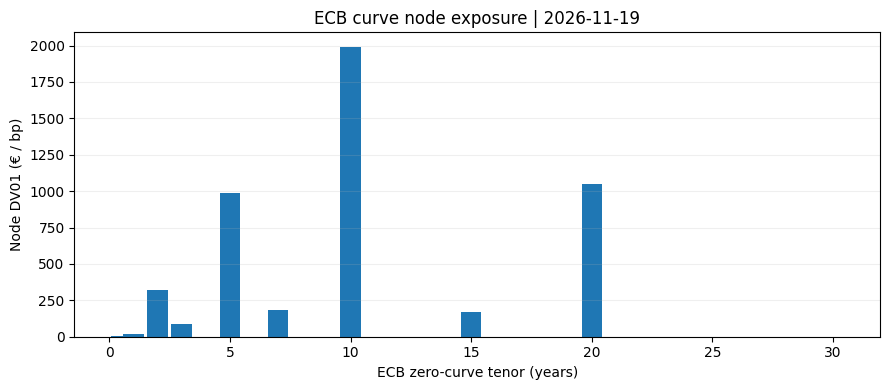

PASS: ECB matched-date curve; fully repriced portfolio; node DV01 reconciliation


In [12]:
ecb_kr=[]
for i,tenor in enumerate(ECB_TENORS):
    up=ECB_ZERO.copy();down=ECB_ZERO.copy()
    up[i]+=1e-4;down[i]-=1e-4
    ecb_kr.append((portfolio_value(down)-portfolio_value(up))/2)
ecb_kr_table=pd.DataFrame({"Tenor (years)":ECB_TENORS,
                            "ECB node DV01 (€ / bp)":ecb_kr,
                            "Illustrative node DV01 (€ / bp)":kr})
display(ecb_kr_table.round(2))
assert np.isclose(np.sum(ecb_kr),ecb_parallel_dv01,rtol=2e-6,atol=.01)
ecb_kr_table.to_csv("ecb_key_rate_exposures.csv",index=False)
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(ECB_TENORS,ecb_kr,width=.85)
ax.set(xlabel="ECB zero-curve tenor (years)",ylabel="Node DV01 (€ / bp)",
       title=f"ECB curve node exposure | {ecb_date.date()}")
ax.grid(axis="y",alpha=.2)
plt.tight_layout();plt.savefig(OUT/"ecb_key_rate_exposures.png",dpi=180,bbox_inches="tight")
plt.show()
print("PASS: ECB matched-date curve; fully repriced portfolio; node DV01 reconciliation")

## Phase 2 conclusion and next steps

The **Phase 1 illustration remains unchanged** as a controlled baseline. Phase 2 adds independently documented ECB AAA euro-area spot-rate inputs for a single observation date. Reported YTMs are *implied by our synthetic cash flows and ECB benchmark curve*, not market quotes for issued government bonds. Data retrieval happens at runtime, so archived executions should always record the observation date.

**Phase 3:** Build portfolio hedges using zero-curve risk nodes and test residual P&L under steepening, flattening and parallel shocks. Avoid treating node-risk matching as exact replication of tradeable bond/futures hedges.

## 12. Phase 3 | Hedge design and financial interpretation

We compare the **unhedged** ECB-repriced bond portfolio with two hypothetical hedges:

1. **Parallel DV01 hedge:** short a 10-year zero-coupon instrument sized to offset total portfolio DV01. It is neutral to **small parallel** zero-curve shifts, but not to nonparallel moves.
2. **5Y / 10Y / 20Y key-rate hedge:** short synthetic zero-coupon instruments with maturities exactly at the three target curve nodes, sized to cancel the portfolio's node-DV01 at those maturities. Because the zero-coupon instrument's cash flow occurs at its own curve node, its risk exposure is local under our interpolation convention. Remaining node exposures are **not** cancelled.

The hedge instruments are **synthetic zero-coupon exposures**, not live traded bonds or futures. Signed quantities represent euro face amounts (negative means short). **These are instantaneous mark-to-market P&L experiments, not self-financing strategy return simulations**: trade proceeds are assumed held as cash at zero return during each instantaneous shock, so we compare changes in marked values only. Shorting costs, repo, cash funding, margin, roll, bid/ask, liquidity, maturity settlement and counterparty exposure are omitted. We do not claim the results show implementable transaction sizes.

In [13]:
# A signed zero-coupon instrument settles at one of the published curve nodes.
from dataclasses import dataclass

@dataclass(frozen=True)
class ZeroHedge:
    label: str
    maturity: float
    face_eur: float  # signed: short < 0, long > 0

    def value(self, rates):
        return self.face_eur * np.exp(-self.maturity * spot(self.maturity, ECB_TENORS, rates))


def hedge_value(hedges, rates):
    return sum(h.value(rates) for h in hedges)


def node_dv01_of_value(fn, rates, bp=1e-4):
    out=[]
    for i in range(len(rates)):
        up=rates.copy();dn=rates.copy();up[i]+=bp;dn[i]-=bp
        out.append((fn(dn)-fn(up))/2)
    return np.asarray(out)


def total_value(hedges, rates):
    return portfolio_value(rates) + hedge_value(hedges, rates)

base_dv01=np.array(ecb_kr,dtype=float)
assert np.isclose(base_dv01.sum(),ecb_parallel_dv01,atol=0.01)

# Parallel hedge: hedge instrument's parallel DV01, for EUR 1 million signed face.
unit10=ZeroHedge('10Y zero (EUR 1m face)',10.0,1_000_000.0)
unit10_dv01=node_dv01_of_value(lambda z: unit10.value(z),ECB_ZERO).sum()
parallel_face=-ecb_parallel_dv01/unit10_dv01*1_000_000.0
parallel_hedges=[ZeroHedge('10Y zero',10.0,parallel_face)]

# Key-rate hedge: solve a 3x3 node-DV01 risk matrix for hedge face notionals.
target_tenors=[5.0,10.0,20.0]
node_ids=[int(np.where(ECB_TENORS==x)[0][0]) for x in target_tenors]
unit_hedges=[ZeroHedge(f'{x:g}Y zero, EUR 1m face',x,1_000_000.0) for x in target_tenors]
risks=np.column_stack([node_dv01_of_value(lambda z,h=h:h.value(z),ECB_ZERO)
                       for h in unit_hedges])
A=risks[node_ids,:]
assert np.linalg.cond(A)<1e8, 'Hedge risk matrix poorly conditioned'
face_millions=np.linalg.solve(A,-base_dv01[node_ids])
keyrate_hedges=[ZeroHedge(f'{x:g}Y zero',x,float(f*1_000_000.0))
                for x,f in zip(target_tenors,face_millions)]

hedge_positions=pd.DataFrame([
    {'Portfolio':'Parallel DV01 hedge','Instrument':h.label,'Maturity (Y)':h.maturity,
     'Signed face (€)':h.face_eur,'Market value (€)':h.value(ECB_ZERO)}
    for h in parallel_hedges]+[
    {'Portfolio':'Key-rate hedge','Instrument':h.label,'Maturity (Y)':h.maturity,
     'Signed face (€)':h.face_eur,'Market value (€)':h.value(ECB_ZERO)}
    for h in keyrate_hedges])
display(hedge_positions.round(2))
hedge_positions.to_csv('hedge_positions.csv',index=False)
print('Modelled ECB date:',ecb_date.date())
print('Baseline market value: €{:,.2f}'.format(ecb_port))
print('Baseline total curve DV01: €{:,.2f}/bp'.format(ecb_parallel_dv01))

,Portfolio,Instrument,Maturity (Y),Signed face (€),Market value (€)
0,Parallel DV01 hedge,10Y zero,10.0000,"-6,795,181.9400","-4,816,572.2400"
1,Key-rate hedge,5Y zero,5.0000,"-2,322,361.6100","-1,980,136.5900"
2,Key-rate hedge,10Y zero,10.0000,"-2,809,644.0500","-1,991,536.6000"
3,Key-rate hedge,20Y zero,20.0000,"-1,107,887.5600","-525,483.6300"


Modelled ECB date: 2026-11-19
Baseline market value: €7,003,533.89
Baseline total curve DV01: €4,816.57/bp


## 13. Hedge effectiveness: total and key-rate DV01

The 10-year-only hedge should have approximately zero **total** DV01, but it can leave material offsetting positive and negative exposures by tenor. The key-rate hedge should have near-zero **5Y, 10Y and 20Y** DV01, while leaving the shorter/intermediate-tenor residuals. The numerical tests below verify those exact targets.

,Tenor (Y),Unhedged,Parallel DV01 hedge,5/10/20Y key-rate hedge
0,0.5000,5.3600,5.3600,5.3600
1,1.0000,18.3400,18.3400,18.3400
2,2.0000,320.8800,320.8800,320.8800
3,3.0000,84.1200,84.1200,84.1200
4,5.0000,990.0700,990.0700,0.0000
5,7.0000,182.5900,182.5900,182.5900
6,10.0000,"1,991.5400","-2,825.0400",0.0000
7,15.0000,172.7000,172.7000,172.7000
8,20.0000,"1,050.9700","1,050.9700",0.0000
9,30.0000,0.0000,0.0000,0.0000


,Net invested marked value (€),Gross hedge face (€),Total DV01 (€ / bp),Absolute node DV01 (€ / bp),5Y DV01 (€ / bp),10Y DV01 (€ / bp),20Y DV01 (€ / bp)
Strategy,,,,,,,
Unhedged,"7,003,533.8900",0.0000,"4,816.5700","4,816.5700",990.0700,"1,991.5400","1,050.9700"
Parallel DV01 hedge,"2,186,961.6500","6,795,181.9400",-0.0000,"5,650.0700",990.0700,"-2,825.0400","1,050.9700"
5/10/20Y key-rate hedge,"2,506,377.0700","6,239,893.2200",784.0000,784.0000,0.0000,0.0000,0.0000


PASS: parallel DV01 target and three key-rate hedge targets


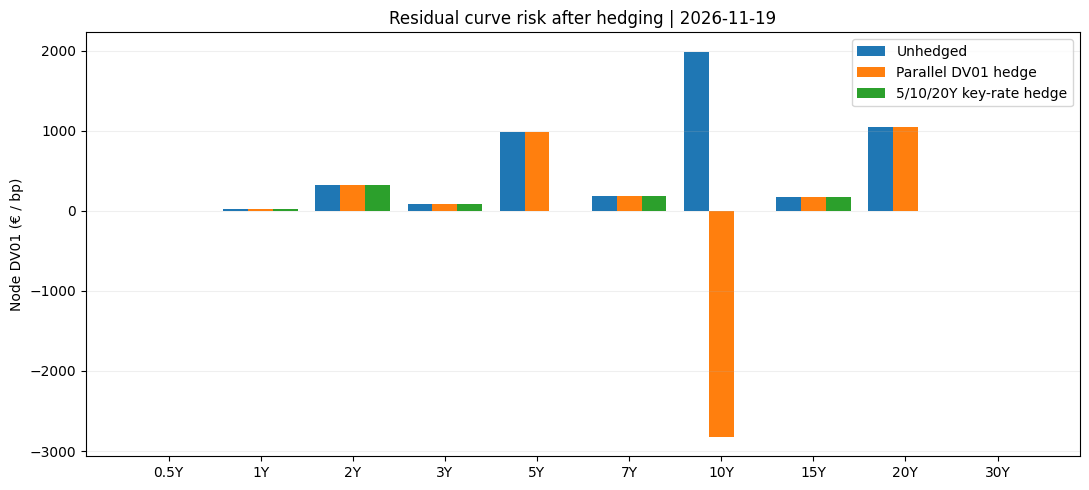

In [14]:
strategies={'Unhedged':[], 'Parallel DV01 hedge':parallel_hedges,
            '5/10/20Y key-rate hedge':keyrate_hedges}
all_risks={name:node_dv01_of_value(lambda z,h=hs:total_value(h,z),ECB_ZERO)
           for name,hs in strategies.items()}
exposure_table=pd.DataFrame({'Tenor (Y)':ECB_TENORS,**{k:v for k,v in all_risks.items()}})
display(exposure_table.round(2))
exposure_table.to_csv('hedged_key_rate_dv01.csv',index=False)

risk_summary=pd.DataFrame([{
    'Strategy':name,
    'Net invested marked value (€)': total_value(hs,ECB_ZERO),
    'Gross hedge face (€)':sum(abs(h.face_eur) for h in hs),
    'Total DV01 (€ / bp)':all_risks[name].sum(),
    'Absolute node DV01 (€ / bp)':np.abs(all_risks[name]).sum(),
    '5Y DV01 (€ / bp)':all_risks[name][node_ids[0]],
    '10Y DV01 (€ / bp)':all_risks[name][node_ids[1]],
    '20Y DV01 (€ / bp)':all_risks[name][node_ids[2]],
} for name,hs in strategies.items()]).set_index('Strategy')
display(risk_summary.round(2))
risk_summary.to_csv('hedge_risk_summary.csv')

assert abs(risk_summary.loc['Parallel DV01 hedge','Total DV01 (€ / bp)'])<0.02
assert np.all(np.abs(all_risks['5/10/20Y key-rate hedge'][node_ids])<0.02)
assert risk_summary.loc['5/10/20Y key-rate hedge','Absolute node DV01 (€ / bp)'] < risk_summary.loc['Unhedged','Absolute node DV01 (€ / bp)']
print('PASS: parallel DV01 target and three key-rate hedge targets')

x=np.arange(len(ECB_TENORS));width=.27
fig,ax=plt.subplots(figsize=(11,5))
for k,(name,risk) in enumerate(all_risks.items()):
    ax.bar(x+(k-1)*width,risk,width,label=name)
ax.set_xticks(x,[f'{z:g}Y' for z in ECB_TENORS])
ax.set(ylabel='Node DV01 (€ / bp)',title=f'Residual curve risk after hedging | {ecb_date.date()}')
ax.grid(axis='y',alpha=.2);ax.legend()
plt.tight_layout();plt.savefig(OUT/'hedge_key_rate_exposure.png',dpi=175,bbox_inches='tight');plt.show()

## 14. Scenario P&L: exact repricing of portfolio and hedge instruments

All three strategies are shocked using **the same curve shifts**. Each row measures `strategy value after shock − strategy value at ECB snapshot`. Hedge market values are negative for short instruments, but any initial cash proceeds are constant during an instantaneous shock and hence cancel from the P&L. The reported "net invested marked value" above is **not a funding-inclusive economic value** and cannot be used as a strategy investment-return denominator.

The scenarios include parallel moves, the Phase 1 bear steepener/bull flattener and an additional **5Y/10Y/20Y local shock** used to inspect risk outside a parallel shift. Finite shifts can generate convexity P&L even when first-order DV01 is zero.

,Unhedged,Parallel DV01 hedge,5/10/20Y key-rate hedge
Scenario,,,
Parallel +100bp,"-457,431.8200",925.6300,"-76,085.6300"
Parallel -100bp,"508,193.2000","1,629.8800","80,874.1700"
Bear steepener,"-400,596.8900","21,290.3500","-51,541.5100"
Bull flattener,"305,747.3800","16,424.1100","65,380.0400"
5Y +75 / 10Y -25 / 20Y +100bp,"-118,104.2300","-240,036.3300",-386.1100


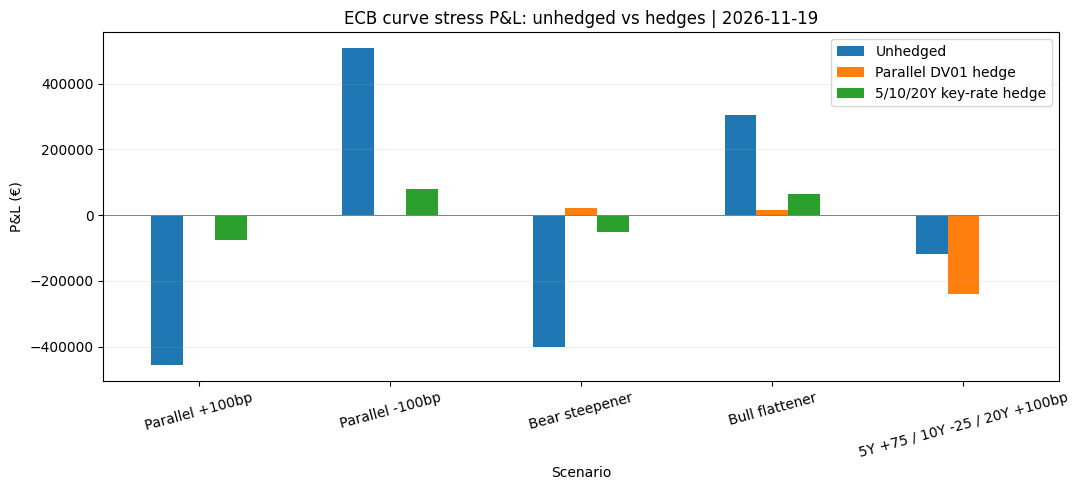

PASS: symmetric 1bp repricing agrees with aggregate DV01 to €0.02


In [15]:
# Add an independently defined nonparallel test (bp shifts linearly across selected nodes).
local_up=np.zeros(len(ECB_TENORS))
for tenor, bp_shift in [(5.0,75),(10.0,-25),(20.0,100)]:
    local_up[np.where(ECB_TENORS==tenor)[0][0]]=bp_shift/10000
all_shifts={**{name:shift for name,shift in scenario_shifts.items() if name!='Base'},
            '5Y +75 / 10Y -25 / 20Y +100bp':local_up}
results=[]
for scenario,shift in all_shifts.items():
    row={'Scenario':scenario}
    for name,hedges in strategies.items():
        row[name]=total_value(hedges,ECB_ZERO+shift)-total_value(hedges,ECB_ZERO)
    results.append(row)
scenario_results=pd.DataFrame(results).set_index('Scenario')
display(scenario_results.round(2))
scenario_results.to_csv('hedged_scenario_pnl.csv')

fig,ax=plt.subplots(figsize=(11,5))
scenario_results.plot(kind='bar',ax=ax)
ax.set(title=f'ECB curve stress P&L: unhedged vs hedges | {ecb_date.date()}',ylabel='P&L (€)')
ax.tick_params(axis='x',rotation=15)
ax.axhline(0,color='gray',lw=.7);ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.savefig(OUT/'hedged_scenario_pnl.png',dpi=175,bbox_inches='tight');plt.show()

# Independent small-shock check: first-order P&L ≈ -DV01 × shock in bp.
small_shift=np.full(len(ECB_TENORS),0.0001)  # 1bp parallel
for name,hs in strategies.items():
    centered=(total_value(hs,ECB_ZERO-small_shift)-total_value(hs,ECB_ZERO+small_shift))/2
    linear=all_risks[name].sum()
    assert abs(centered-linear)<0.02, (name,centered,linear)
print('PASS: symmetric 1bp repricing agrees with aggregate DV01 to €0.02')

## 15. Results and next phase

- The **parallel hedge** neutralizes small parallel rate moves by design, but can leave substantial curve-shape exposure and positive convexity.
- The **three-node hedge** cancels modelled local exposures at 5, 10 and 20 years, leaving other node risk. It is not a complete hedge against arbitrary twists, nor is it automatically superior for every finite scenario.
- **Model assumptions matter:** the ECB AAA curve is a benchmark not an instrument-specific tradable curve; synthetic zero-coupon hedge notionals are idealized; actual bond yields reflect liquidity and credit spread and hedging instruments introduce basis, financing and operational risk.
- These are **instantaneous deterministic shocks**, not statistical VaR, P&L forecasts or portfolio return strategies.

**Phase 4:** produce a complete dashboard, research report and GitHub package with dated market-data evidence, model assumptions, scenario charts, hedge attribution, test checks and limitations. Download the executed Colab notebook and tables for that final package.